In [2]:
from google.colab import drive
drive .mount('/content/drive')

Mounted at /content/drive


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

df = pd.read_csv('/content/drive/MyDrive/CodeAlpha_Task/car data.csv')

print(df.head())
print(df.info())

  Car_Name  Year  Selling_Price  Present_Price  Driven_kms Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Selling_type Transmission  Owner  
0       Dealer       Manual      0  
1       Dealer       Manual      0  
2       Dealer       Manual      0  
3       Dealer       Manual      0  
4       Dealer       Manual      0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  3

In [5]:
# Preprocess the data
df = df.dropna()
df = df.drop(columns=['Car_Name'])
df = pd.get_dummies(df, drop_first=True)
print(df.head())

   Year  Selling_Price  Present_Price  Driven_kms  Owner  Fuel_Type_Diesel  \
0  2014           3.35           5.59       27000      0             False   
1  2013           4.75           9.54       43000      0              True   
2  2017           7.25           9.85        6900      0             False   
3  2011           2.85           4.15        5200      0             False   
4  2014           4.60           6.87       42450      0              True   

   Fuel_Type_Petrol  Selling_type_Individual  Transmission_Manual  
0              True                    False                 True  
1             False                    False                 True  
2              True                    False                 True  
3              True                    False                 True  
4             False                    False                 True  


In [6]:
# Select input features and target variable
X = df.drop('Selling_Price', axis=1)
y = df['Selling_Price']
# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# Train the Random Forest Regression model
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)
# Predict car prices
predictions = model.predict(X_test)

In [7]:
# Evaluate model performance
print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R2 Score:", r2_score(y_test, predictions))

Mean Absolute Error: 0.5971295081967213
R2 Score: 0.9643601062650229


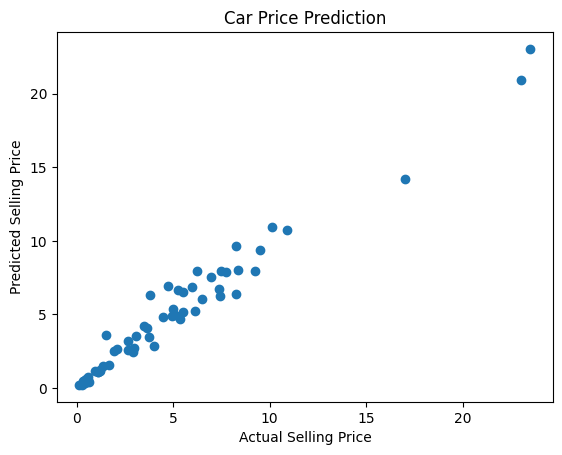

In [8]:
# Visualize actual and predicted prices
plt.scatter(y_test, predictions)
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Car Price Prediction")
plt.show()

In [9]:
# Predict the price of one car
new_car = X_test.iloc[[0]]
predicted_price = model.predict(new_car)
print("Predicted Car Price:", predicted_price[0], "lakhs")

Predicted Car Price: 0.44410000000000005 lakhs
